# So sánh thực nghiệm IaaS, PaaS và FaaS cho cùng API

**Phúc Hoàng – Benchmark + Chi phí + Phân tích**

Notebook tái lập pipeline từ raw data. Mặc định dùng **SIMULATED DATA – NOT REAL CLOUD MEASUREMENTS**. Không sử dụng dữ liệu mô phỏng làm bằng chứng thực nghiệm GCP.

## 1. Mục tiêu và câu hỏi nghiên cứu

So sánh latency, throughput, tỷ lệ lỗi, cold/warm, phản ứng scale-out và chi phí với cùng input, seed data và endpoint mix. Chênh lệch tài nguyên, concurrency và billing phải được ghi nhận riêng.

## 2. Thiết kế và mô tả dữ liệu

Đơn vị thí nghiệm độc lập là một **run**. Request trong cùng run có thể tương quan. Raw k6 là JSONL Point; Monitoring giữ nguyên scalar/distribution, labels và intervals. Metadata chứa nguồn, config, seed và thời gian UTC. DEMO có 5 vòng; không xác nhận cloud đã được đo.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'configs').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from benchmark.config import load_config
from benchmark.parsers import load_dataset
from benchmark.statistics.analysis import analyze, bootstrap_ci
from benchmark.cost.model import CostModel
from benchmark.cost.report import cost_report
from benchmark.io import DEMO_LABEL, read_json
config = load_config()
MODE = os.environ.get('BENCH_MODE', 'DEMO').upper()
assert MODE in {'DEMO', 'REAL'}
DATA_ROOT = Path(os.environ.get('BENCH_DATA_ROOT', 'demo_data' if MODE == 'DEMO' else 'results'))
ANALYSIS = Path('results/processed') / MODE.lower()
FINANCIAL = Path('results/financial') / MODE.lower()
display(Markdown('**' + (DEMO_LABEL if MODE == 'DEMO' else 'REAL: kiểm tra validity từng run') + '**'))

**SIMULATED DATA – NOT REAL CLOUD MEASUREMENTS**

## 3. Đọc dữ liệu

Thay `BENCH_MODE=REAL` và `BENCH_DATA_ROOT` để đọc phép đo mới. Không tự tạo mẫu khi dữ liệu thật bị thiếu.

In [2]:
requests, metadata, raw_metrics, quality = load_dataset(DATA_ROOT)
assert metadata, 'Chưa có metadata; chạy demo hoặc cung cấp raw dataset thật'
assert {m['data_mode'] for m in metadata.values()} == {MODE}, 'Không trộn các data modes'
display(requests.head())
display(pd.DataFrame([{'run_id': key, 'model': m['model'], 'scenario': m['scenario'], 'mode': m['data_mode']} for key, m in metadata.items()]).head())

,timestamp,request_id,run_id,model,scenario,load_level,endpoint,phase,latency_ms,wall_ms,handler_ms,status,success,classification,instance_id,error_code,data_mode,scenario_start_ms,error_type,outlier
0,2026-10-01 09:59:57.035625+00:00,simulated-faas-burst-burst-mixed-r01-0,simulated-faas-burst-burst-mixed-r01,faas,burst,burst,read,warmup,35.625141,37.625141,25.650102,200,True,confirmed_warm,sim-faas-10-1,,DEMO,1.790849e+12,none,False
1,2026-10-01 09:59:57.139362+00:00,simulated-faas-burst-burst-mixed-r01-1,simulated-faas-burst-burst-mixed-r01,faas,burst,burst,read,warmup,39.362421,41.362421,28.340943,200,True,unknown,sim-faas-10-1,,DEMO,1.790849e+12,none,False
2,2026-10-01 09:59:57.240832+00:00,simulated-faas-burst-burst-mixed-r01-2,simulated-faas-burst-burst-mixed-r01,faas,burst,burst,read,warmup,40.831876,42.831876,29.398950,200,True,confirmed_warm,sim-faas-10-1,,DEMO,1.790849e+12,none,False
3,2026-10-01 09:59:57.374480+00:00,simulated-faas-burst-burst-mixed-r01-3,simulated-faas-burst-burst-mixed-r01,faas,burst,burst,read,warmup,74.480461,76.480461,53.625932,200,True,confirmed_warm,sim-faas-10-1,,DEMO,1.790849e+12,none,False
4,2026-10-01 09:59:57.434451+00:00,simulated-faas-burst-burst-mixed-r01-4,simulated-faas-burst-burst-mixed-r01,faas,burst,burst,read,warmup,34.450552,36.450552,24.804397,200,True,unknown,sim-faas-10-1,,DEMO,1.790849e+12,none,False


,run_id,model,scenario,mode
0,simulated-faas-burst-burst-mixed-r01,faas,burst,DEMO
1,simulated-faas-burst-burst-mixed-r02,faas,burst,DEMO
2,simulated-faas-burst-burst-mixed-r03,faas,burst,DEMO
3,simulated-faas-burst-burst-mixed-r04,faas,burst,DEMO
4,simulated-faas-burst-burst-mixed-r05,faas,burst,DEMO


## 4. Kiểm tra tính hợp lệ

Kiểm tra timestamp UTC, missing fields, duplicate và schema. Bản sao làm sạch loại dòng không thể phân tích và duplicate chính xác; duplicate xung đột được cách ly. Raw luôn giữ nguyên.

In [3]:
display(pd.DataFrame([{'run_id': k, 'valid_rows': v.get('valid_rows'), 'invalid_rows': v.get('invalid_rows'), 'duplicates': v.get('duplicates'), 'warmup_rows': v.get('warmup_rows')} for k,v in quality.items()]).head(12))
assert requests['latency_ms'].ge(0).all()
assert requests['timestamp'].dt.tz is not None

,run_id,valid_rows,invalid_rows,duplicates,warmup_rows
0,simulated-faas-burst-burst-mixed-r01,860,0,0,30
1,simulated-faas-burst-burst-mixed-r02,860,0,0,30
2,simulated-faas-burst-burst-mixed-r03,860,0,0,30
3,simulated-faas-burst-burst-mixed-r04,860,0,0,30
4,simulated-faas-burst-burst-mixed-r05,860,0,0,30
5,simulated-faas-idle-idle-mixed-r01,21,0,0,0
6,simulated-faas-idle-idle-mixed-r02,21,0,0,0
7,simulated-faas-idle-idle-mixed-r03,21,0,0,0
8,simulated-faas-idle-idle-mixed-r04,21,0,0,0
9,simulated-faas-idle-idle-mixed-r05,21,0,0,0


## 5. Làm sạch dữ liệu

Dữ liệu warm-up không nằm trong steady measurement. Request lỗi và outlier hợp lệ được giữ. Unknown outcome không được mặc định là thành công. Phân loại first request cấp ứng dụng không đồng nghĩa confirmed cold.

In [4]:
measured = requests.loc[requests['phase'].isin(['measurement', 'first_after_idle'])].copy()
display(measured.groupby(['model', 'classification']).size().unstack(fill_value=0))
display(measured.groupby('model')[['latency_ms','handler_ms','wall_ms']].count())

classification,confirmed_cold,confirmed_warm,unknown
model,,,
faas,4,10356,645
iaas,0,10381,624
paas,4,10328,673


,latency_ms,handler_ms,wall_ms
model,,,
faas,11005,10567,11005
iaas,11005,10558,11005
paas,11005,10559,11005


## 6. Khám phá dữ liệu

Phân phối latency có thể lệch phải. Không xóa đuôi phân phối để làm đẹp kết quả. Nhóm medium steady được dùng cho biểu đồ minh họa sau.

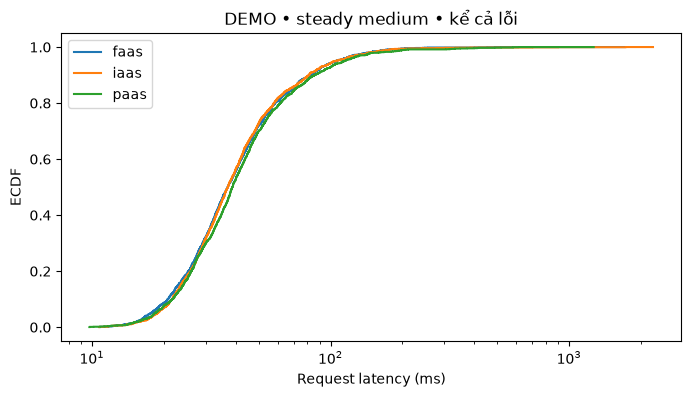

In [5]:
cohort = measured.loc[(measured['scenario']=='steady') & (measured['load_level']=='medium')]
if len(cohort):
    fig, ax = plt.subplots(figsize=(8,4))
    for model, group in cohort.groupby('model'):
        x=np.sort(group['latency_ms']); ax.step(x, np.arange(1,len(x)+1)/len(x), label=model)
    ax.set(xscale='log', xlabel='Request latency (ms)', ylabel='ECDF', title=MODE+' • steady medium • kể cả lỗi')
    ax.legend(); plt.show()
else: print('Thiếu nhóm steady medium')

## 7. Thống kê hiệu năng

Percentile dùng nội suy tuyến tính NumPy. Standard deviation dùng `ddof=1`. Achieved throughput = completions trong cửa sổ / duration; cohort throughput bao gồm request measurement kết thúc trong grace period. Goodput và error rate được xuất riêng.

In [6]:
tables = analyze(DATA_ROOT, ANALYSIS, resamples=config['experiments']['bootstrap_resamples'], minimum_samples=config['experiments']['minimum_samples'])
per_run=tables['per_run']; comparison=tables['comparison']
display(per_run.loc[per_run['endpoint']=='all', ['run_id','request_count','p50_ms','p95_ms','p99_ms','achieved_rps','error_rate_pct','valid_for_comparison']].head(12))

,run_id,request_count,p50_ms,p95_ms,p99_ms,achieved_rps,error_rate_pct,valid_for_comparison
0,simulated-faas-burst-burst-mixed-r01,830,60.300290,172.471192,252.824604,41.500000,1.566265,True
4,simulated-faas-burst-burst-mixed-r02,830,48.221026,137.765448,252.338665,41.500000,1.325301,True
8,simulated-faas-burst-burst-mixed-r03,830,59.562369,171.929345,308.787258,41.500000,1.807229,True
12,simulated-faas-burst-burst-mixed-r04,830,48.647238,148.372386,247.647156,41.500000,0.963855,True
16,simulated-faas-burst-burst-mixed-r05,830,58.504724,176.066281,352.705292,41.500000,0.602410,True
20,simulated-faas-idle-idle-mixed-r01,21,57.176987,165.637917,574.833340,1.044975,9.523810,False
24,simulated-faas-idle-idle-mixed-r02,21,35.311552,86.840598,122.098909,1.048363,0.000000,False
28,simulated-faas-idle-idle-mixed-r03,21,34.626410,142.214593,321.208664,1.049277,0.000000,False
32,simulated-faas-idle-idle-mixed-r04,21,43.411608,110.982536,603.664659,1.048165,4.761905,False
36,simulated-faas-idle-idle-mixed-r05,21,42.545613,104.697575,1197.125039,1.047191,0.000000,False


## 8. Khoảng tin cậy bootstrap

Estimand = trung bình thống kê theo run, không phải percentile của request gộp. Bootstrap 2.000 lần từ các run hợp lệ độc lập. Dưới 2 run: không có CI. Dưới 5 run: cảnh báo; p99 dưới 1.000 mẫu/run thiếu ổn định. CI là bất định lấy mẫu có điều kiện, không bao phủ mọi sai số cloud.

In [7]:
display(comparison.loc[(comparison['metric']=='p95_ms') & (comparison['endpoint']=='all')].head(12))
display(pd.DataFrame([bootstrap_ci([10,20,30,40,50], seed=20261031)]))

,data_mode,model,scenario,load_level,endpoint,metric,estimate,ci_lower,ci_upper,number_of_runs,bootstrap_method,resamples,status,sample_size,estimand
1,DEMO,faas,burst,burst,all,p95_ms,161.320930,146.827985,173.800858,5,percentile_bootstrap_of_independent_run_means,2000,OK,4150,mean_of_run_statistics
25,DEMO,faas,steady,high,all,p95_ms,125.861117,119.744523,131.752868,5,percentile_bootstrap_of_independent_run_means,2000,OK,4500,mean_of_run_statistics
49,DEMO,faas,steady,low,all,p95_ms,116.056754,91.716483,137.621003,5,percentile_bootstrap_of_independent_run_means,2000,OK,450,mean_of_run_statistics
61,DEMO,faas,steady,medium,all,p95_ms,105.329287,91.175524,122.683654,5,percentile_bootstrap_of_independent_run_means,2000,OK,1800,mean_of_run_statistics
85,DEMO,iaas,burst,burst,all,p95_ms,196.048787,181.464761,211.550125,5,percentile_bootstrap_of_independent_run_means,2000,OK,4150,mean_of_run_statistics
109,DEMO,iaas,steady,high,all,p95_ms,126.104535,117.346803,139.623137,4,percentile_bootstrap_of_independent_run_means,2000,FEW_RUNS,3600,mean_of_run_statistics
133,DEMO,iaas,steady,low,all,p95_ms,98.286554,91.152078,105.421031,5,percentile_bootstrap_of_independent_run_means,2000,OK,450,mean_of_run_statistics
145,DEMO,iaas,steady,medium,all,p95_ms,104.960130,100.247148,112.239182,5,percentile_bootstrap_of_independent_run_means,2000,OK,1800,mean_of_run_statistics
169,DEMO,paas,burst,burst,all,p95_ms,142.943029,132.149204,153.970835,5,percentile_bootstrap_of_independent_run_means,2000,OK,4150,mean_of_run_statistics
193,DEMO,paas,steady,high,all,p95_ms,122.308901,110.975072,131.764740,5,percentile_bootstrap_of_independent_run_means,2000,OK,4500,mean_of_run_statistics


,estimate,ci_lower,ci_upper,number_of_runs,bootstrap_method,resamples,status
0,30.0,18.0,42.0,5,percentile_bootstrap_of_independent_run_means,2000,OK


## 9. Steady-load

Đọc low/medium/high riêng. Offered RPS là mục tiêu phát, achieved là số đo hoàn thành. Dropped iterations và generator saturation làm run không đủ giá trị so sánh chính thức.

In [8]:
steady=per_run.loc[(per_run['scenario']=='steady') & (per_run['endpoint']=='all')]
display(steady.groupby(['model','load_level'])[['p95_ms','achieved_rps','offered_rps','error_rate_pct']].mean())
display(steady.loc[~steady['valid_for_comparison'], ['run_id','warning']])

p95_ms  achieved_rps  offered_rps  error_rate_pct
model load_level                                                       
faas  high        125.861117     49.866667         50.0        1.422222
      low         116.056754      5.000000          5.0        1.777778
      medium      105.329287     20.000000         20.0        1.777778
iaas  high        125.407522     49.888889         50.0        0.955556
      low          98.286554      5.000000          5.0        0.666667
      medium      104.960130     19.966667         20.0        1.388889
paas  high        122.308901     49.888889         50.0        1.311111
      low          99.675104      5.000000          5.0        1.333333
      medium      112.624676     19.988889         20.0        1.444444

,run_id,warning
140,simulated-iaas-steady-high-mixed-r01,DROPPED_ITERATIONS


## 10. Burst-load

Dùng cửa sổ 10 giây, phân biệt baseline/burst/recovery. Với burst DEMO ngắn, một bin có thể cắt nhiều pha; khi đo thật cần chọn bin phù hợp.

In [9]:
timeline=tables['timeline']
burst=timeline.loc[timeline['scenario']=='burst'] if len(timeline) else timeline
display(burst.head(12))
if len(burst): display(burst.groupby(['model','burst_phase'])[['p95_ms','p99_ms','achieved_rps','error_rate_pct']].mean())

,data_mode,run_id,model,scenario,relative_seconds,burst_phase,request_count,achieved_rps,p95_ms,p99_ms,error_rate_pct
0,DEMO,simulated-faas-burst-burst-mixed-r01,faas,burst,0,baseline,454,45.4,174.928866,256.633023,2.422907
1,DEMO,simulated-faas-burst-burst-mixed-r01,faas,burst,10,burst,376,37.6,164.125402,232.807935,0.531915
2,DEMO,simulated-faas-burst-burst-mixed-r02,faas,burst,0,baseline,455,45.5,142.519567,267.249893,1.758242
3,DEMO,simulated-faas-burst-burst-mixed-r02,faas,burst,10,burst,375,37.5,129.970534,232.461332,0.800000
4,DEMO,simulated-faas-burst-burst-mixed-r03,faas,burst,0,baseline,454,45.4,154.469775,225.226604,1.321586
5,DEMO,simulated-faas-burst-burst-mixed-r03,faas,burst,10,burst,376,37.6,193.103632,418.239791,2.393617
6,DEMO,simulated-faas-burst-burst-mixed-r04,faas,burst,0,baseline,456,45.6,149.956641,235.062582,1.096491
7,DEMO,simulated-faas-burst-burst-mixed-r04,faas,burst,10,burst,374,37.4,144.163670,252.276558,0.802139
8,DEMO,simulated-faas-burst-burst-mixed-r05,faas,burst,0,baseline,452,45.2,163.176215,272.874860,1.106195
9,DEMO,simulated-faas-burst-burst-mixed-r05,faas,burst,10,burst,378,37.8,187.520367,373.402070,0.000000


p95_ms      p99_ms  achieved_rps  error_rate_pct
model burst_phase                                                      
faas  baseline     157.010213  251.409393         45.42        1.541084
      burst        163.776721  301.837538         37.58        0.905534
iaas  baseline     195.645728  320.774364         45.04        1.554899
      burst        201.836235  329.407766         37.96        1.319029
paas  baseline     136.726355  234.362452         45.46        1.538860
      burst        151.754372  232.921302         37.52        1.120016

## 11. Cold / warm

Confirmed cold yêu cầu bằng chứng nền tảng độc lập liên kết request. Process-first-request chỉ đo lần đầu tiến trình. Unknown giữ riêng. Idle 20 phút không bảo đảm scale-to-zero. Chênh lệch median cold/warm không phải phép đo chính xác overhead hạ tầng.

In [10]:
display(tables['cold_warm'].head(12))
display(tables['cold_penalty'].head(12))

,data_mode,model,scenario,endpoint,run_id,classification,request_count,mean_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms,std_ms,cv,tail_warning,handler_mean_ms,wall_mean_ms
0,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r01,confirmed_warm,80,179.203254,157.189410,263.034752,NaN,51.196236,1488.745412,160.344041,0.894761,"p95 requires >=20, p99 requires >=1000 samples...",129.508933,181.203254
1,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r01,unknown,3,213.859982,250.666364,NaN,NaN,130.980028,259.933552,71.925553,0.336321,"p95 requires >=20, p99 requires >=1000 samples...",153.979187,215.859982
2,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r02,confirmed_warm,76,147.568793,127.011315,275.711064,NaN,56.410148,505.282245,75.459177,0.511349,"p95 requires >=20, p99 requires >=1000 samples...",107.583411,149.568793
3,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r02,unknown,8,137.087859,120.551441,NaN,NaN,68.178765,283.951394,69.074251,0.503868,"p95 requires >=20, p99 requires >=1000 samples...",101.768706,139.087859
4,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r03,confirmed_warm,84,161.348145,153.218607,281.016465,NaN,61.672689,356.139584,61.727325,0.382572,"p95 requires >=20, p99 requires >=1000 samples...",116.773446,163.348145
5,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r03,unknown,6,101.303073,98.612915,NaN,NaN,75.682048,130.102186,20.978714,0.207089,"p95 requires >=20, p99 requires >=1000 samples...",72.938213,103.303073
6,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r04,confirmed_warm,93,158.895836,133.776639,264.038006,NaN,49.701554,1702.559989,173.774806,1.093640,"p95 requires >=20, p99 requires >=1000 samples...",114.516122,160.895836
7,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r04,unknown,3,182.908362,189.743365,NaN,NaN,165.921717,193.060004,14.804041,0.080937,"p95 requires >=20, p99 requires >=1000 samples...",128.039430,184.908362
8,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r05,confirmed_warm,74,195.206637,171.377643,363.330989,NaN,75.534784,406.813143,86.949551,0.445423,"p95 requires >=20, p99 requires >=1000 samples...",139.982069,197.206637
9,DEMO,faas,burst,cpu,simulated-faas-burst-burst-mixed-r05,unknown,4,145.913213,147.223564,NaN,NaN,87.980056,201.225668,56.111976,0.384557,"p95 requires >=20, p99 requires >=1000 samples...",105.057513,147.913213


,data_mode,model,scenario,endpoint,estimate,ci_lower,ci_upper,number_of_runs,bootstrap_method,resamples,status,method
0,DEMO,faas,burst,cpu,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
1,DEMO,faas,burst,read,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
2,DEMO,faas,burst,write,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
3,DEMO,faas,idle,cpu,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
4,DEMO,faas,idle,read,550.152203,NaN,NaN,3,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
5,DEMO,faas,idle,write,1427.686292,NaN,NaN,1,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
6,DEMO,faas,steady,cpu,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
7,DEMO,faas,steady,read,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
8,DEMO,faas,steady,write,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...
9,DEMO,iaas,burst,cpu,NaN,NaN,NaN,0,percentile_bootstrap_of_independent_run_means,2000,INSUFFICIENT_DATA,mean paired-run difference of cold/warm median...


## 12. Scale-out

Cloud Monitoring thường sampling 60 giây và trễ hiển thị. Thời gian scale-out được xác định bằng khoảng giữa sample cuối trước tăng và sample đầu quan sát tăng. IaaS một VM cố định: không áp dụng autoscaling; không biểu diễn 0 giây.

In [11]:
display(tables['scaling'].head(15))
monitor=tables['monitoring']
if len(monitor): display(monitor.groupby(['model','metric'])['value'].agg(['count','mean']))

,data_mode,run_id,model,scenario,status,scale_out_seconds,scale_out_lower_seconds,scale_out_upper_seconds,baseline_instances,peak_instances,recovery_seconds,sampling_seconds,burst_started_at,observed_increase_at,peak_at
0,DEMO,simulated-faas-burst-burst-mixed-r01,faas,burst,OBSERVED_INTERVAL,54.0,0.0,54.0,1.0,2.0,106.0,60.0,2026-10-01T10:00:06+00:00,2026-10-01T10:01:00+00:00,2026-10-01T10:01:00+00:00
1,DEMO,simulated-faas-burst-burst-mixed-r02,faas,burst,OBSERVED_INTERVAL,54.0,0.0,54.0,1.0,2.0,106.0,60.0,2026-10-02T01:00:06+00:00,2026-10-02T01:01:00+00:00,2026-10-02T01:01:00+00:00
2,DEMO,simulated-faas-burst-burst-mixed-r03,faas,burst,OBSERVED_INTERVAL,54.0,0.0,54.0,1.0,2.0,106.0,60.0,2026-10-02T16:00:06+00:00,2026-10-02T16:01:00+00:00,2026-10-02T16:01:00+00:00
3,DEMO,simulated-faas-burst-burst-mixed-r04,faas,burst,OBSERVED_INTERVAL,54.0,0.0,54.0,1.0,2.0,106.0,60.0,2026-10-03T07:00:06+00:00,2026-10-03T07:01:00+00:00,2026-10-03T07:01:00+00:00
4,DEMO,simulated-faas-burst-burst-mixed-r05,faas,burst,OBSERVED_INTERVAL,54.0,0.0,54.0,1.0,2.0,106.0,60.0,2026-10-03T21:00:06+00:00,2026-10-03T21:01:00+00:00,2026-10-03T21:01:00+00:00
5,DEMO,simulated-faas-idle-idle-mixed-r01,faas,idle,NOT_APPLICABLE_SCENARIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,DEMO,simulated-faas-idle-idle-mixed-r02,faas,idle,NOT_APPLICABLE_SCENARIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,DEMO,simulated-faas-idle-idle-mixed-r03,faas,idle,NOT_APPLICABLE_SCENARIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,DEMO,simulated-faas-idle-idle-mixed-r04,faas,idle,NOT_APPLICABLE_SCENARIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,DEMO,simulated-faas-idle-idle-mixed-r05,faas,idle,NOT_APPLICABLE_SCENARIO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


count        mean
model metric                                   
faas  billable_instance_time    100   12.000000
      cpu                       100    0.446146
      instance_count            100    1.050000
      memory                     80    0.472629
      startup_latency           100  296.873536
iaas  cpu                       100    0.490724
      memory                    100    0.503409
paas  billable_instance_time    100   12.000000
      cpu                       100    0.443594
      instance_count            100    1.050000
      memory                    100    0.435739
      startup_latency           100  302.631914

## 13. Mô hình chi phí

Giá Singapore có URL và bản chụp nguồn. CPU-seconds không được tính bằng N × p95. Estimator dùng mean service demand, CPU demand, overlap/concurrency, hourly traffic profile và startup assumptions; measurements billable-instance-time cần đúng kỳ/volume. Request-based khác instance-based. VM thanh toán full host e2-standard-2 dù container chỉ 1 vCPU/1 GiB. Firestore là chi phí chung nhưng retries cần khai báo theo mô hình.

In [12]:
cost_input=Path(os.environ.get('BENCH_COST_WORKLOAD','configs/cost_workloads.yaml'))
cost_model=CostModel.from_files(Path('configs/pricing_catalog.yaml'),cost_input)
assert cost_model.workload['data_mode']==MODE, 'Đổi cost workload data_mode và assumptions cho phép đo REAL'
financial=cost_report(cost_model, FINANCIAL)
display(financial['cost_levels'][['model','level','monthly_requests','total_usd','compute_usd','shared_data_usd','capacity_status']])

,model,level,monthly_requests,total_usd,compute_usd,shared_data_usd,capacity_status
0,iaas,low,100000,61.018852,60.346282,0.23257,UNVERIFIED
1,paas,low,100000,0.644377,0.371807,0.23257,ESTIMATED_SUPPORTED
2,faas,low,100000,0.644377,0.371807,0.23257,ESTIMATED_SUPPORTED
3,iaas,medium,2000000,61.930282,60.346282,1.14400,UNVERIFIED
4,paas,medium,2000000,8.971869,7.027869,1.14400,ESTIMATED_SUPPORTED
5,faas,medium,2000000,8.971869,7.027869,1.14400,ESTIMATED_SUPPORTED
6,iaas,high,20000000,70.564882,60.346282,9.77860,UNVERIFIED
7,paas,high,20000000,66.233804,48.455204,9.77860,ESTIMATED_SUPPORTED
8,faas,high,20000000,66.233804,48.455204,9.77860,ESTIMATED_SUPPORTED


## 14. Điểm hòa vốn

Hàm chi phí có thể không giao nhau, có nhiều nghiệm hoặc trùng nhau trong khoảng. Tìm nghiệm kiểm tra residual để không tạo nghiệm giả ở bước nhảy. Log grid hữu hạn có thể bỏ sót tiếp xúc hẹp; bổ sung breakpoints khi dùng model bậc phức tạp. Nghiệm tài chính không chứng minh cả hai mô hình đáp ứng SLA/capacity.

In [13]:
break_even=read_json(FINANCIAL/'break_even.json')
display(pd.DataFrame([{'left': x['left'],'right': x['right'],'status':x['status'],'roots':x['roots'],'coincident_intervals':x['coincident_intervals']} for x in break_even]))

,left,right,status,roots,coincident_intervals
0,iaas,paas,ROOTS_FOUND,[22234780.990233496],[]
1,iaas,faas,ROOTS_FOUND,[22234780.990233496],[]
2,paas,faas,COINCIDENT_INTERVAL,[],"[[0.0, 1000000000.0]]"


## 15. Sensitivity analysis

Thay từng giả định: CPU time, memory, mix, response size, concurrency, traffic peak, active hours, min instances, giá và công lao động. Giá trị baseline bằng 0 có thể làm sensitivity bằng 0; đó là điều kiện mô hình, không phải bằng chứng chi phí không tồn tại.

In [14]:
sensitivity=financial['sensitivity']
display(sensitivity.assign(abs_delta=sensitivity['delta_usd'].abs()).sort_values('abs_delta',ascending=False).head(15))

,data_mode,model,parameter,direction,base_usd,total_usd,delta_usd,capacity_status,note,abs_delta
19,DEMO,iaas,price_multiplier,high,61.930282,92.895423,30.965141,UNVERIFIED,,30.965141
18,DEMO,iaas,price_multiplier,low,61.930282,30.965141,-30.965141,UNVERIFIED,,30.965141
61,DEMO,faas,min_instances,high,8.971869,25.790206,16.818337,ESTIMATED_SUPPORTED,,16.818337
39,DEMO,paas,min_instances,high,8.971869,25.790206,16.818337,ESTIMATED_SUPPORTED,,16.818337
41,DEMO,paas,price_multiplier,high,8.971869,13.457803,4.485934,ESTIMATED_SUPPORTED,,4.485934
63,DEMO,faas,price_multiplier,high,8.971869,13.457803,4.485934,ESTIMATED_SUPPORTED,,4.485934
62,DEMO,faas,price_multiplier,low,8.971869,4.485934,-4.485934,ESTIMATED_SUPPORTED,,4.485934
40,DEMO,paas,price_multiplier,low,8.971869,4.485934,-4.485934,ESTIMATED_SUPPORTED,,4.485934
22,DEMO,paas,monthly_requests,low,8.971869,4.674445,-4.297424,ESTIMATED_SUPPORTED,,4.297424
44,DEMO,faas,monthly_requests,low,8.971869,4.674445,-4.297424,ESTIMATED_SUPPORTED,,4.297424


## 16. So sánh ba mô hình và SLA

Không gộp các workload khác nhau thành một xếp hạng duy nhất. Bảng performance và bảng cost có phạm vi khác nhau; cần hiệu chỉnh mean service/CPU/profile trước khi liên hệ chúng. INCONCLUSIVE là kết quả hợp lệ khi thiếu bằng chứng.

In [15]:
from benchmark.decision_engine.report import case_studies
cases=case_studies(Path('reports/generated')/MODE.lower()/'decision')
display(pd.DataFrame([{'case':x['case'],'recommendation':x['result']['recommendation'],'status':x['result']['status']} for x in cases]))

,case,recommendation,status
0,API container cần portability cao,PAAS,DEMO_ONLY
1,Sự kiện gián đoạn,FAAS,DEMO_ONLY
2,Cần quyền OS,IAAS,DEMO_ONLY
3,Cold SLA nghiêm ngặt,IAAS,DEMO_ONLY
4,Peak vượt phạm vi đã đo,INCONCLUSIVE,INSUFFICIENT_DATA
5,"Background lâu, chưa xác minh timeout",INCONCLUSIVE,INSUFFICIENT_DATA
6,Không đủ ngân sách,INCONCLUSIVE,INSUFFICIENT_DATA
7,Chưa có dữ liệu thật,INCONCLUSIVE,INSUFFICIENT_DATA


## 17. Sai số và threats to validity

Network jitter; contention; caching; Firestore indexes/retries; khác biệt hardware và container limits; concurrency/workers/timeout; load generator bottleneck; quota; thời gian chạy ngắn; cold classification; sampling; giá thay đổi và workload không đại diện. Xem `reports/limitations.md` cho nguyên nhân, ảnh hưởng, giảm thiểu và giới hạn còn lại của từng yếu tố.

## 18. Nhận xét từ kết quả quan sát

Phần dưới sinh số lượng run và trạng thái thực tế từ bảng; không viết sẵn nền tảng nhanh nhất/rẻ nhất.

In [16]:
valid=per_run.loc[(per_run['endpoint']=='all') & per_run['valid_for_comparison']]
display(Markdown(f'Có **{len(metadata)} run**, trong đó **{len(valid)}** run có đủ điều kiện hiện tại.'))
if MODE=='DEMO':
    display(Markdown('**Không có kết luận thực nghiệm GCP từ notebook DEMO.** Các số liệu chỉ xác minh pipeline chạy được.'))
else:
    display(Markdown('Kết quả chỉ áp dụng các cấu hình/run hợp lệ. Cần kiểm tra CI, capacity, SLA và threats to validity trước khi kết luận.'))

Có **75 run**, trong đó **59** run có đủ điều kiện hiện tại.

**Không có kết luận thực nghiệm GCP từ notebook DEMO.** Các số liệu chỉ xác minh pipeline chạy được.

## 19. Tái lập và xuất kết quả

Chạy `python -m benchmark.cli export` sau analyze/cost để tạo PNG 300 DPI, SVG, HTML và báo cáo Markdown. Raw data bất biến. Lưu source Git SHA, dependency lock, source hashes, config, seed và experiment metadata cùng kết quả.